## Этап 1: EDA

In [1]:
%matplotlib inline

import pandas as pd

df_r = pd.read_csv( 'ratings.csv' )
df_b = pd.read_csv( 'books.csv' )
df_t = pd.read_csv( 'tags.csv' )
df_bt = pd.read_csv( 'book_tags.csv')


In [2]:
df_b.head(20)

,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...
5,6,11870085,11870085,16827462,226,525478817,9.780525e+12,John Green,2012.0,The Fault in Our Stars,...,2346404,2478609,140739,47994,92723,327550,698471,1311871,https://images.gr-assets.com/books/1360206420m...,https://images.gr-assets.com/books/1360206420s...
6,7,5907,5907,1540236,969,618260307,9.780618e+12,J.R.R. Tolkien,1937.0,The Hobbit or There and Back Again,...,2071616,2196809,37653,46023,76784,288649,665635,1119718,https://images.gr-assets.com/books/1372847500m...,https://images.gr-assets.com/books/1372847500s...
7,8,5107,5107,3036731,360,316769177,9.780317e+12,J.D. Salinger,1951.0,The Catcher in the Rye,...,2044241,2120637,44920,109383,185520,455042,661516,709176,https://images.gr-assets.com/books/1398034300m...,https://images.gr-assets.com/books/1398034300s...
8,9,960,960,3338963,311,1416524797,9.781417e+12,Dan Brown,2000.0,Angels & Demons,...,2001311,2078754,25112,77841,145740,458429,716569,680175,https://images.gr-assets.com/books/1303390735m...,https://images.gr-assets.com/books/1303390735s...
9,10,1885,1885,3060926,3455,679783261,9.780680e+12,Jane Austen,1813.0,Pride and Prejudice,...,2035490,2191465,49152,54700,86485,284852,609755,1155673,https://images.gr-assets.com/books/1320399351m...,https://images.gr-assets.com/books/1320399351s...


In [3]:
df_r.head()

,user_id,book_id,rating
0,1,258,5
1,2,4081,4
2,2,260,5
3,2,9296,5
4,2,2318,3


In [4]:
df_r.describe()

,user_id,book_id,rating
count,5.976479e+06,5.976479e+06,5.976479e+06
mean,2.622446e+04,2.006477e+03,3.919866e+00
std,1.541323e+04,2.468499e+03,9.910868e-01
min,1.000000e+00,1.000000e+00,1.000000e+00
25%,1.281300e+04,1.980000e+02,3.000000e+00
50%,2.593800e+04,8.850000e+02,4.000000e+00
75%,3.950900e+04,2.973000e+03,5.000000e+00
max,5.342400e+04,1.000000e+04,5.000000e+00


### Распределение оценок

In [5]:
df_r['rating'].value_counts(normalize = True)

rating
4    0.357906
5    0.331816
3    0.229385
2    0.060112
1    0.020781
Name: proportion, dtype: float64

<Axes: >

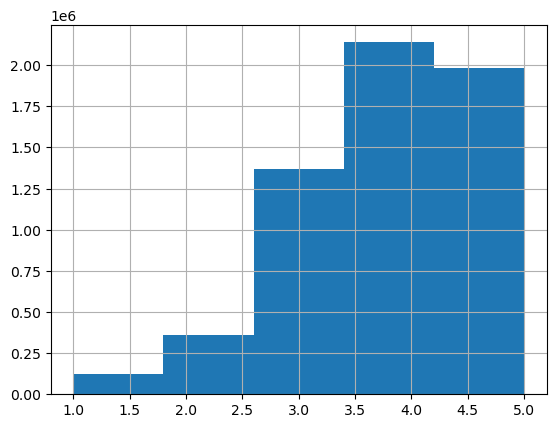

In [6]:
df_r.rating.hist( bins = 5 )

Есть смещение в пользу высоких оценок - распространены четврки и пятерки (35.8% и 33.2% соответственно)

### Анализ активности пользователей

In [7]:
user_activity = (
    df_r.groupby('user_id')
    .size()
    .rename('n_ratings')
)

user_activity.describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)

count    53424.000000
mean       111.868804
std         26.071224
min         19.000000
10%         82.000000
25%         96.000000
50%        111.000000
75%        128.000000
90%        146.000000
95%        157.000000
99%        176.000000
max        200.000000
Name: n_ratings, dtype: float64

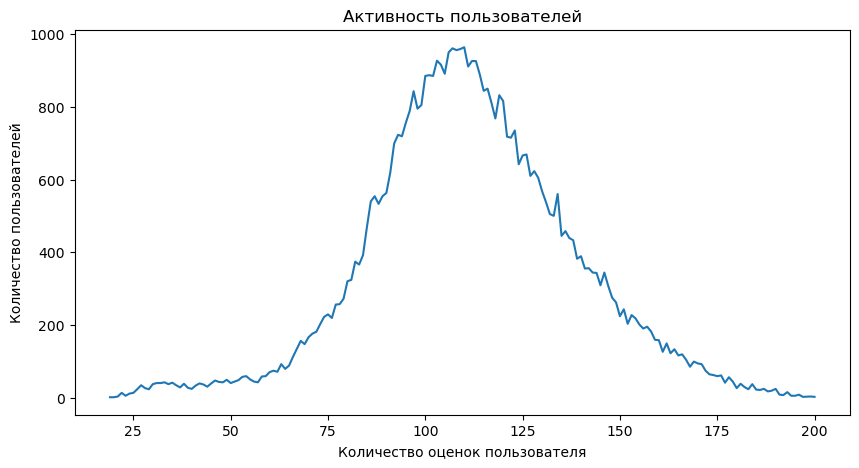

In [8]:
import matplotlib.pyplot as plt

users_by_activity = (
    user_activity
    .value_counts()
    .sort_index()
    .reset_index()
)

plt.figure(figsize=(10, 5))

plt.plot(
    users_by_activity['n_ratings'],
    users_by_activity['count']
)

plt.xlabel('Количество оценок пользователя')
plt.ylabel('Количество пользователей')
plt.title('Активность пользователей')

plt.show()

In [9]:
users_by_activity['frac_users'] = users_by_activity['count']*100/users_by_activity['count'].sum()
users_by_activity['frac_users_cumsum'] = users_by_activity['frac_users'].cumsum()

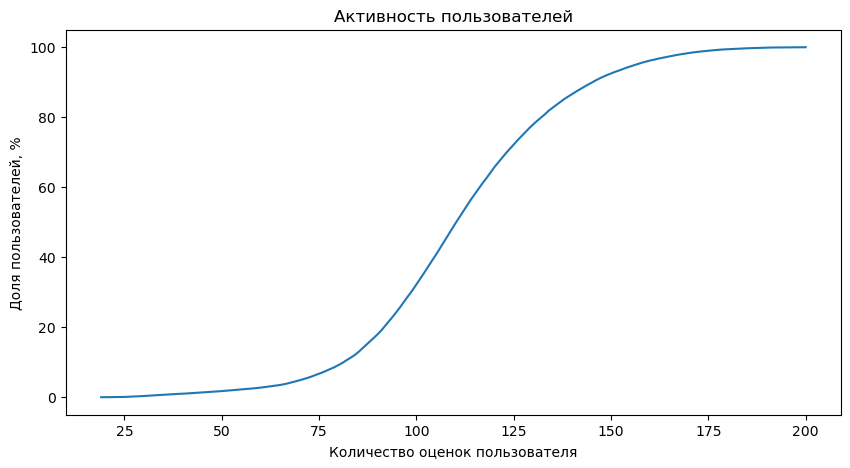

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    users_by_activity['n_ratings'],
    users_by_activity['frac_users_cumsum']
)

plt.xlabel('Количество оценок пользователя')
plt.ylabel('Доля пользователей, %')
plt.title('Активность пользователей')

plt.show()

- Распределение количества оценок по пользователям схоже с нормальным, аномального числа оценок нет ни по нижней, ни по верхней границы (19 оценок снизу и 200 сверху). Хвост распределения немного тяжелее справа

### Анализ популярности книг

 Топ 20 самых популярных книг

In [11]:
book_stats = (
    df_r
    .groupby('book_id')
    .agg(
        n_ratings=('rating', 'size'),
        mean_rating=('rating', 'mean')
    )
    .reset_index()
)

book_stats = book_stats.merge(
    df_b[['book_id',
            'title',
            'original_title',
            'authors']],
    on='book_id',
    how='left'
)

In [12]:
book_stats.sort_values('n_ratings', ascending=False).head(20)

,book_id,n_ratings,mean_rating,title,original_title,authors
0,1,22806,4.279707,"The Hunger Games (The Hunger Games, #1)",The Hunger Games,Suzanne Collins
1,2,21850,4.351350,Harry Potter and the Sorcerer's Stone (Harry P...,Harry Potter and the Philosopher's Stone,"J.K. Rowling, Mary GrandPré"
3,4,19088,4.329369,To Kill a Mockingbird,To Kill a Mockingbird,Harper Lee
2,3,16931,3.214341,"Twilight (Twilight, #1)",Twilight,Stephenie Meyer
4,5,16604,3.772224,The Great Gatsby,The Great Gatsby,F. Scott Fitzgerald
16,17,16549,4.133422,"Catching Fire (The Hunger Games, #2)",Catching Fire,Suzanne Collins
19,20,15953,3.853131,"Mockingjay (The Hunger Games, #3)",Mockingjay,Suzanne Collins
17,18,15855,4.418732,Harry Potter and the Prisoner of Azkaban (Harr...,Harry Potter and the Prisoner of Azkaban,"J.K. Rowling, Mary GrandPré, Rufus Beck"
22,23,15657,4.229418,Harry Potter and the Chamber of Secrets (Harry...,Harry Potter and the Chamber of Secrets,"J.K. Rowling, Mary GrandPré"
6,7,15558,4.148477,The Hobbit,The Hobbit or There and Back Again,J.R.R. Tolkien


Саммари статистика по оценкам книг

In [13]:
book_rate_count = (
book_stats.groupby(['n_ratings'], as_index = False)
.agg({'book_id':'count'})
.rename(columns = {'book_id': 'n_books'})
)

In [14]:
book_rate_count['n_ratings'].describe()

count     1902.000000
mean      1875.399054
std       2475.340999
min          8.000000
25%        520.250000
50%       1074.500000
75%       2154.500000
max      22806.000000
Name: n_ratings, dtype: float64

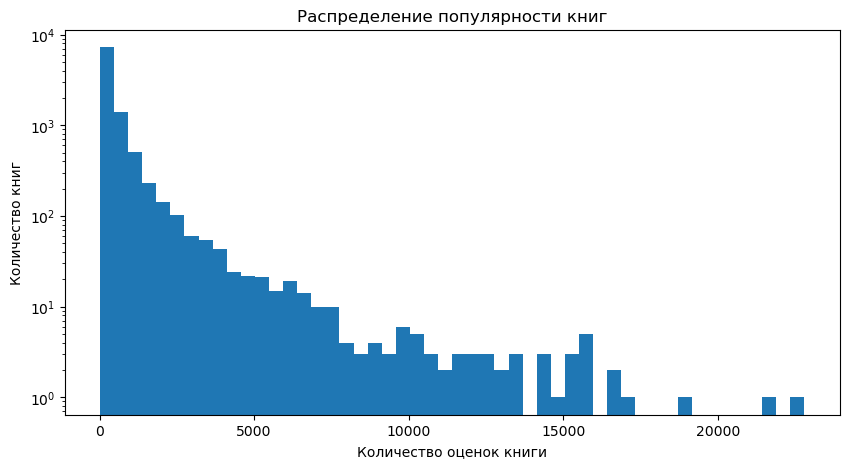

In [15]:
import seaborn as sns

plt.figure(figsize=(10, 5))

plt.hist(book_stats['n_ratings'], bins=50)
plt.yscale('log')

plt.ylabel('Количество книг')
plt.xlabel('Количество оценок книги')
plt.title('Распределение популярности книг')

plt.show()

In [16]:
sorted_counts = (
    book_stats['n_ratings']
    .sort_values(ascending=False)
)

total_interactions = sorted_counts.sum()

for fraction in [0.01, 0.05, 0.10, 0.20]:
    n_books = max(1, int(len(sorted_counts)*fraction))

    interaction_share = (sorted_counts.iloc[:n_books].sum()/total_interactions)

    print(
        f'Top {fraction:.0%} books account for '
        f'{interaction_share:.2%} of ratings'
    )

Top 1% books account for 17.09% of ratings
Top 5% books account for 40.15% of ratings
Top 10% books account for 53.20% of ratings
Top 20% books account for 67.50% of ratings


In [17]:
tags_full = df_bt.merge(
    df_t,
    on='tag_id',
    how='left'
)

Самые популярные теги

In [18]:
tag_popularity = (
    tags_full
    .groupby('tag_name', as_index = False)
    .agg({'count':'sum'})
    .sort_values(by = ['count'], ascending=False)
)

tag_popularity.head(30)

,tag_name,count
30574,to-read,140718761
8717,currently-reading,7507958
11557,favorites,4503173
11743,fiction,3688819
11305,fantasy,3548157
33114,young-adult,1848306
7457,classics,1756920
5207,books-i-own,1317235
26138,romance,1231926
22743,owned,1224279


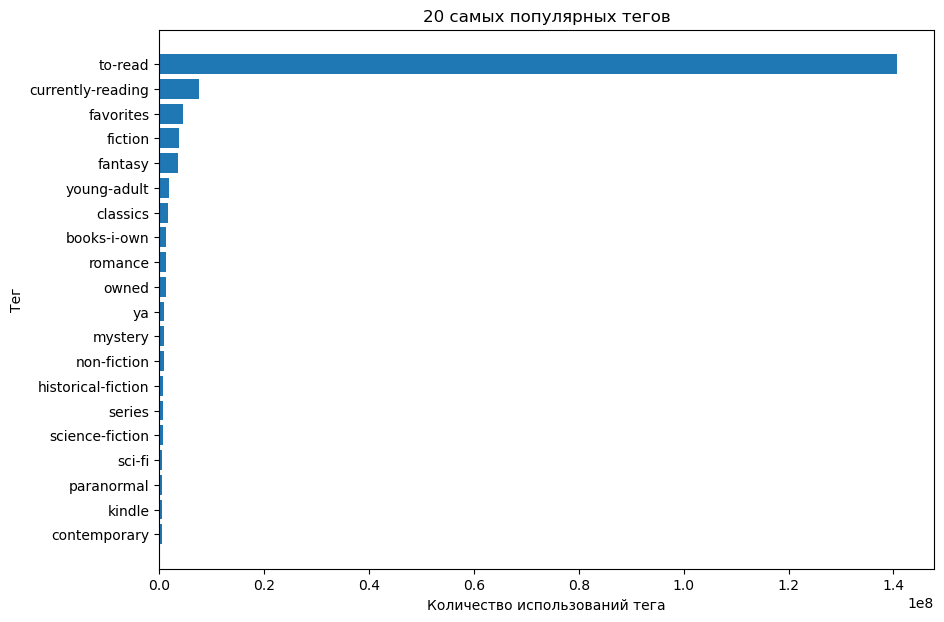

In [19]:
top_tags_plot = tag_popularity.head(20).sort_values('count')

plt.figure(figsize=(10, 7))
plt.barh(top_tags_plot['tag_name'], top_tags_plot['count'])
plt.xlabel('Количество использований тега')
plt.ylabel('Тег')
plt.title('20 самых популярных тегов')
plt.show()

In [20]:
n_users = df_r['user_id'].nunique()
n_books = df_r['book_id'].nunique()
n_ratings = len(df_r)

possible_interactions = n_users*n_books

density = n_ratings/possible_interactions
sparsity = 1 - density

print(f'Users: {n_users:,}')
print(f'Books: {n_books:,}')
print(f'Observed interactions: {n_ratings:,}')

print(f'Density: {density:.3%}')
print(f'Sparsity: {sparsity:.3%}')

Users: 53,424
Books: 10,000
Observed interactions: 5,976,479
Density: 1.119%
Sparsity: 98.881%


### Выводы по проблемам в данных
- Данные достаточно разрезежены 98.88% - большинство пользователей не взаимодействоали с большей частью товаров
- При этом есть смещение оценок в пользу популярных книг, 20% топовых наименований отвечают за 67.5% всех оценок
- Пользовательская активность нормальная - нет признаков активности ботов, распределнеи близко к нормальному. Пользователей с нулём оценок в датасете нет (минимум - 19), поэтому холодный старт новых пользователей напрямую не наблюдается
- Шкала пользовательских оценок смещена в пользу положительных - наиболее популярны оценки 4 и 5 (а не медианная оценка 3 например), что создает некоторый positivity-bias 

## Этап 2: Базовые и контентные модели

### Неперсонализированная модель
Реализуем алгоритм, который выдает топ N книг по средней оценке с минимальным рейтингом >= 100 (можно варьировать)

In [21]:
popularity_stats = (
    df_r
    .groupby('book_id')
    .agg(
        mean_rating=('rating', 'mean'),
        n_ratings=('rating', 'count')
    )
    .reset_index()
)

popularity_stats = popularity_stats.merge(
    df_b[['book_id', 'title', 'original_title', 'authors']],
    on='book_id',
    how='left'
)

popularity_stats.head()

,book_id,mean_rating,n_ratings,title,original_title,authors
0,1,4.279707,22806,"The Hunger Games (The Hunger Games, #1)",The Hunger Games,Suzanne Collins
1,2,4.351350,21850,Harry Potter and the Sorcerer's Stone (Harry P...,Harry Potter and the Philosopher's Stone,"J.K. Rowling, Mary GrandPré"
2,3,3.214341,16931,"Twilight (Twilight, #1)",Twilight,Stephenie Meyer
3,4,4.329369,19088,To Kill a Mockingbird,To Kill a Mockingbird,Harper Lee
4,5,3.772224,16604,The Great Gatsby,The Great Gatsby,F. Scott Fitzgerald


In [22]:
def recommend_top_n_books(N=10, min_ratings=100):
    recommendations = (
        popularity_stats[
            popularity_stats['n_ratings'] >= min_ratings
        ]
        .sort_values(
            ['mean_rating', 'n_ratings'],
            ascending=[False, False]
        )
        .head(N)
    )
    
    return recommendations[
        [
            'book_id',
            'title',
            'authors',
            'mean_rating',
            'n_ratings'
        ]
    ]

In [23]:
recommend_top_n_books(10, 1000)

,book_id,title,authors,mean_rating,n_ratings
861,862,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson,4.702840,1373
779,780,Calvin and Hobbes,"Bill Watterson, G.B. Trudeau",4.661406,1394
421,422,"Harry Potter Boxset (Harry Potter, #1-7)",J.K. Rowling,4.659530,1915
1009,1010,The Essential Calvin and Hobbes: A Calvin and ...,Bill Watterson,4.652522,1249
1263,1264,"Queen of Shadows (Throne of Glass, #4)",Sarah J. Maas,4.564007,1078
561,562,"The Way of Kings (The Stormlight Archive, #1)",Brandon Sanderson,4.545556,1789
24,25,Harry Potter and the Deathly Hallows (Harry Po...,"J.K. Rowling, Mary GrandPré",4.525941,15304
963,964,J.R.R. Tolkien 4-Book Boxed Set: The Hobbit an...,J.R.R. Tolkien,4.518571,1400
191,192,The Name of the Wind (The Kingkiller Chronicle...,Patrick Rothfuss,4.499747,3948
1021,1022,"Heir of Fire (Throne of Glass, #3)",Sarah J. Maas,4.484919,1293


### Контентная модель
Реализуем алгоритм который для книги по названию будет выдавать топ N похожих на нее на основе текстового профиля и списка тегов

In [24]:
tags_full = df_bt.merge(
    df_t,
    on='tag_id',
    how='left'
)

In [25]:
book_tags_full = tags_full.merge(
    df_b[['book_id',
            'goodreads_book_id',
            'title',
            'original_title']],
    on='goodreads_book_id',
    how='inner'
)

In [26]:
book_tags_full.sort_values(['goodreads_book_id', 'count'], ascending = False, inplace = True)

In [27]:
top_book_tags = book_tags_full.groupby(['goodreads_book_id']).head(15)

In [28]:
top_book_tags

,goodreads_book_id,tag_id,count,tag_name,book_id,title,original_title
999812,33288638,30574,14116,to-read,8892,Wait for It,Wait for It
999813,33288638,8717,1196,currently-reading,8892,Wait for It,Wait for It
999814,33288638,26138,385,romance,8892,Wait for It,Wait for It
999815,33288638,11557,354,favorites,8892,Wait for It,Wait for It
999816,33288638,8055,216,contemporary,8892,Wait for It,Wait for It
...,...,...,...,...,...,...,...
10,1,27199,3857,series,27,Harry Potter and the Half-Blood Prince (Harry ...,Harry Potter and the Half-Blood Prince
11,1,11590,3456,favourites,27,Harry Potter and the Half-Blood Prince (Harry ...,Harry Potter and the Half-Blood Prince
12,1,18886,3374,magic,27,Harry Potter and the Half-Blood Prince (Harry ...,Harry Potter and the Half-Blood Prince
13,1,6953,2408,childrens,27,Harry Potter and the Half-Blood Prince (Harry ...,Harry Potter and the Half-Blood Prince


In [29]:
df_b = df_b.merge(
    (top_book_tags.groupby(['goodreads_book_id'])['tag_name']
    .apply(lambda x: ' '.join(x.astype(str)))
    ).reset_index()
    .rename(columns = {'tag_name': 'string_top_tags'}),
    on = ['goodreads_book_id'],
    how = 'left'
)

In [30]:
df_b['string_top_tags'] = df_b['string_top_tags'].fillna('')

In [31]:
df_b['book_title_and_tags'] = df_b['original_title'] + ' ' + df_b['string_top_tags']

In [32]:
df_b['book_title_and_tags'] = df_b['book_title_and_tags'].fillna('').str.lower()

In [33]:
df_b.shape

(10000, 25)

In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    max_features=20000
)

tfidf_matrix = tfidf.fit_transform(df_b['book_title_and_tags'])

In [35]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(tfidf_matrix)

In [36]:
similarity_matrix[0]

array([1.        , 0.15390265, 0.11787337, ..., 0.02895596, 0.02672485,
       0.0170526 ], shape=(10000,))

In [37]:
top5_idx = similarity_matrix.argsort(axis=1)[:, ::-1][:, 1:6]

In [38]:
import numpy as np

top5_similarities = np.take_along_axis(
    similarity_matrix,
    top5_idx,
    axis=1
)

In [39]:
def get_similar_books(book_title, N=5):
    if isinstance(book_title, str):
        matches = df_b[df_b['original_title'] == book_title]
    else:
        matches = df_b[df_b['book_id'] == book_title]

    if not matches.empty:
        idx_book = matches.index[0]
        print(f'Топ {N} книг которые похожи на "{book_title}"')
        indices = (top5_idx[idx_book][:N] if N <= 5
                   else similarity_matrix[idx_book].argsort()[::-1][:N])
        return df_b.iloc[indices][['book_id', 'original_title', 'authors', 'original_publication_year']]
    else:
        return "Книга с таким названием или book_id не найдена"

In [40]:
get_similar_books("The Great Gatsby")

Топ 5 книг которые похожи на "The Great Gatsby"


,book_id,original_title,authors,original_publication_year
137,138,The Scarlet Letter,"Nathaniel Hawthorne, Thomas E. Connolly, Nina ...",1850.0
594,595,A Separate Peace,John Knowles,1959.0
159,160,Great Expectations,Charles Dickens,1860.0
300,301,Heart of Darkness,Joseph Conrad,1899.0
3,4,To Kill a Mockingbird,Harper Lee,1960.0


## Этап 3: коллаборативная фильтрация (Collaborative Filtering — CF)

In [41]:
df_r.shape

(5976479, 3)

In [42]:
df_r.columns

Index(['user_id', 'book_id', 'rating'], dtype='object')

In [43]:
df_r[['user_id', 'book_id']].drop_duplicates().shape

(5976479, 2)

In [44]:
from scipy.sparse import csr_matrix

def build_item_user_sparse(ratings):
    book_ids = np.sort(ratings['book_id'].unique())
    user_ids = np.sort(ratings['user_id'].unique())

    item_user = csr_matrix(
        (
            ratings['rating'].to_numpy(dtype=np.float32),
            (
                pd.Index(book_ids).get_indexer(ratings['book_id']),
                pd.Index(user_ids).get_indexer(ratings['user_id'])
            )
        ),
        shape=(len(book_ids), len(user_ids))
    )
    return item_user, book_ids

item_user_matrix, book_ids_cf = build_item_user_sparse(df_r)

In [45]:
item_user_matrix.shape

(10000, 53424)

In [48]:
from sklearn.metrics.pairwise import cosine_similarity

item_similarity = pd.DataFrame(
    cosine_similarity(item_user_matrix),
    index=book_ids_cf,
    columns=book_ids_cf
)

item_similarity.shape

(10000, 10000)

In [49]:
def predict_item_cf(user_id, book_id, item_similarity, ratings_df, K=20):

    global_mean = ratings_df['rating'].mean()

    if book_id not in item_similarity.index:
        return global_mean

    user_ratings = ratings_df[ratings_df['user_id'] == user_id][['book_id', 'rating']].copy()

    if user_ratings.empty:
        return global_mean

    # target-книгу не используем для предсказания самой себя
    user_ratings = user_ratings[user_ratings['book_id'] != book_id]

    # оставляем книги, существующие в similarity matrix
    user_ratings = user_ratings[user_ratings['book_id'].isin(item_similarity.columns)]

    if user_ratings.empty:
        return global_mean

    # similarity target-книги
    # с книгами, которые оценивал пользователь
    similarities = item_similarity.loc[book_id, user_ratings['book_id']]

    user_ratings['similarity'] = similarities.values

    # берём K наиболее похожих книг
    neighbors = (
        user_ratings
        .sort_values(
            'similarity',
            ascending=False
        )
        .head(K)
    )

    denominator = neighbors['similarity'].abs().sum()

    if denominator == 0:
        return global_mean

    prediction = (neighbors['rating']*neighbors['similarity']).sum()/denominator

    print(f'Для пользователя {user_id} предсказанный рейтинг книги {book_id} составит {prediction:.2f}')

    return np.clip(prediction, 1, 5)

In [50]:
predict_item_cf(1, 10, item_similarity, df_r)

Для пользователя 1 предсказанный рейтинг книги 10 составит 3.57


np.float64(3.573345857328002)

**Ограничения подхода CF**
- Сложность подхода CF в данной реализации заключается в том, что для I количества книг и N количества юзеров операция косинусовой близости имеет вычислительную сложность $O(I^2U)$, а хранение полной матрицы схожести книг объем памяти $O(I^2)$
- Для более лайт продовой версии алгоритма можно было бы хранить например только K соседей для каждой книги из самых похожих

## Этап 4: матричные разложения

In [187]:
# %pip install scikit-surprise

In [51]:
from surprise import Dataset, Reader, SVD
from surprise.model_selection import train_test_split
from surprise import accuracy

reader = Reader(rating_scale=(1, 5))

df_svd = Dataset.load_from_df(df_r, reader)

In [52]:
df_r.columns

Index(['user_id', 'book_id', 'rating'], dtype='object')

In [53]:
df_train, df_test = train_test_split(df_svd, test_size=0.2, random_state=42)

In [54]:
svd = SVD(n_factors=50, n_epochs=10, lr_all=0.005, reg_all=0.02, random_state=42)

svd.fit(df_train)

In [55]:
pred = svd.test(df_test)

In [56]:
rmse = accuracy.rmse(pred)

RMSE: 0.8496


Ошибка RMSE на тестовой группе составила 0.85 - на столько в среднем ошибается модель в предсказании рейтинга пользователя 

In [57]:
def get_recommendations(user_id, model, df_train, books_df, N=5):
    #проверяем что юзер в сете
    try:
      inner_uid = df_train.to_inner_uid(user_id)
      is_in_train = df_train.knows_user(inner_uid)
    except ValueError:
      print(f'User {user_id} is not in train: False')
      return pd.DataFrame(columns=['book_id', 'rating_estimate', 'title', 'authors'])

    # книги, которые пользователь уже оценил
    rated_inner_items = {
        inner_iid
        for inner_iid, rating
        in df_train.ur[inner_uid]
    }

    # все книги, известные модели
    candidate_inner_items = [
        inner_iid
        for inner_iid in df_train.all_items()
        if inner_iid not in rated_inner_items
    ]

    recommendations = []

    for inner_iid in candidate_inner_items:
        book_id = df_train.to_raw_iid(inner_iid)
        pred = model.predict(user_id, book_id)
        recommendations.append((book_id, pred.est))

    recommendations_s = sorted(recommendations, key=lambda x: x[1], reverse=True)[:N]
    res_df = pd.DataFrame(recommendations_s, columns = ['book_id', 'rating_estimate'])
    res_df = res_df.merge(books_df[['book_id', 'title', 'authors']], on = 'book_id', how = 'left')

    return res_df

In [58]:
get_recommendations(1, svd, df_train, df_b, 5)

,book_id,rating_estimate,title,authors
0,8946,4.507027,The Divan,Hafez
1,3628,4.494123,The Complete Calvin and Hobbes,Bill Watterson
2,6590,4.445244,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson
3,862,4.442421,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson
4,6361,4.431939,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson


## Этап 5: оценка и сравнение моделей

- Разделим датасет на обучающую и тестовую группу и для чистоты эксперимента будем замерять точность исключительно на одних и тех же пользовательских оценках
- Для каждого ранее реализованного подхода подготовим функцию которая будет по user_id выдавать N рекомендаций в виде списка book_id
- Затем оценим метрики Precision@K, Recall@K, nDCG@K (Normalized Discounted Cumulative Gain) на test выборке

In [59]:
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df_r, test_size=0.2, random_state=42)

### Popularity-based на train выборке

In [60]:
popularity_stats_train = (df_train.groupby('book_id')
    .agg(
        mean_rating=('rating', 'mean'),
        n_ratings=('rating', 'count')
    )
    .reset_index())

popularity_stats_train = popularity_stats_train.merge(
    df_b[['book_id', 'title', 'authors']],
    on='book_id',
    how='left'
)

In [61]:
MIN_RATINGS = 100

popular_ranking = (
    popularity_stats_train[popularity_stats_train['n_ratings'] >= MIN_RATINGS]
    .sort_values(
        ['mean_rating', 'n_ratings'],
        ascending=[False, False]
    )
    ['book_id']
    .tolist()
)

In [62]:
def get_recs_for_users_by_popularity(user_id, df_train, popular_ranking, N=5):
    
    seen_books = df_train[df_train['user_id'] == user_id]['book_id'].to_list()
    recommendations = [book_id for book_id in popular_ranking if book_id not in seen_books][:N]

    return recommendations

In [63]:
get_recs_for_users_by_popularity(1, df_train, popular_ranking)

[8978, 3628, 9566, 6920, 5207]

### Item_similarity на train выборке

In [64]:
user_book_matrix = df_train.pivot_table(
    index="user_id", columns="book_id", values="rating", fill_value=0
)

item_user_matrix = user_book_matrix.T

item_similarity_train = pd.DataFrame(
    cosine_similarity(item_user_matrix),
    index=item_user_matrix.index,
    columns=item_user_matrix.index
)

In [65]:
global_mean_train = df_train['rating'].mean()

def get_recs_for_users_by_item_similarity(user_id, item_similarity, ratings_df, N=5, K_neighbors=20):
    user_ratings = (
        ratings_df[ratings_df['user_id'] == user_id][['book_id', 'rating']]
        .copy()
    )

    if user_ratings.empty:
        return []
        
    user_ratings = user_ratings[user_ratings['book_id'].isin(item_similarity.columns)]

    if user_ratings.empty:
        return []

    rated_books = user_ratings['book_id'].to_numpy()

    ratings = user_ratings['rating'].to_numpy(dtype=np.float32)

    sims = item_similarity.loc[:,rated_books].to_numpy(copy=False)

    k = min(K_neighbors,len(rated_books))

    top_k_idx = np.argpartition(sims, -k, axis=1)[:, -k:]

    top_k_sims = np.take_along_axis(sims, top_k_idx, axis=1)

    neighbor_ratings = ratings[top_k_idx]

    numerator = (top_k_sims*neighbor_ratings).sum(axis=1)

    denominator = np.abs(top_k_sims).sum(axis=1)

    scores = np.divide(
        numerator,
        denominator,
        out=np.full(
            len(item_similarity),
            global_mean_train,
            dtype=np.float32
        ),
        where=denominator!=0
    )

    scores = pd.Series(scores, index=item_similarity.index)

    # уже оценённые книги не рекомендуем
    scores.loc[scores.index.isin(rated_books)] = -np.inf

    recommendations = (
        scores
        .nlargest(N)
        .index
        .tolist()
    )

    return recommendations

In [66]:
get_recs_for_users_by_item_similarity(1, item_similarity_train, df_train)

[3722, 5416, 2652, 6862, 8255]

### SVD

In [67]:
reader = Reader(rating_scale=(1, 5))

df_svd_train = Dataset.load_from_df(df_train, reader)
df_svd_test = Dataset.load_from_df(df_test, reader)

In [68]:
df_svd_train = df_svd_train.build_full_trainset()

In [69]:
svd = SVD(n_factors=50, n_epochs=10, lr_all=0.005, reg_all=0.02, random_state=42)

In [70]:
svd.fit(df_svd_train)

In [71]:
def get_recs_for_svd(user_id, model, df_train, N=5):
    try:
        inner_uid = df_train.to_inner_uid(user_id)
    except ValueError:
        return []

    scores = df_train.global_mean + model.bu[inner_uid] + model.bi + model.qi@model.pu[inner_uid]
    scores = scores.copy()

    rated_inner_items = [inner_iid for inner_iid, rating in df_train.ur[inner_uid]]

    scores[rated_inner_items] = -np.inf

    top_idx = np.argpartition(scores, -N)[-N:]
    top_idx = top_idx[np.argsort(scores[top_idx])[::-1]]

    recommendations = [df_train.to_raw_iid(inner_iid) for inner_iid in top_idx]

    return recommendations

In [72]:
get_recs_for_svd(1, svd, df_svd_train)

[3628, 8946, 7947, 9566, 5207]

### Оценка моделей на test выборке

In [73]:
def ranking_metrics_at_k(recommended, relevant, K=5):
    
    recommended = list(recommended[:K])
    relevant = set(relevant)

    if len(relevant) == 0:
        return np.nan, np.nan, np.nan

    relevance_vector = np.array([1 if item in relevant else 0 for item in recommended])

    hits = relevance_vector.sum()

    # Precision@K
    precision = hits/K

    # Recall@K
    recall = hits/len(relevant)

    # DCG@K
    discounts = 1/np.log2(np.arange(2, len(relevance_vector) + 2))
    dcg = (relevance_vector*discounts).sum()

    # ideal DCG
    ideal_hits = min(len(relevant), K)
    ideal_relevance = np.ones(ideal_hits)
    ideal_discounts = 1 / np.log2(np.arange(2, ideal_hits + 2))
    idcg = (ideal_relevance*ideal_discounts).sum()

    ndcg = (dcg/idcg if idcg > 0 else 0)

    return (precision, recall, ndcg)

In [74]:
RELEVANCE_THRESHOLD = 4
train_catalog = set(df_train['book_id'].unique())
relevant_test = df_test[(df_test['rating'] >= RELEVANCE_THRESHOLD) & (df_test['book_id'].isin(train_catalog))].copy()
relevant_by_user = (relevant_test.groupby('user_id')['book_id'].apply(set).to_dict())

train_users = set(df_train['user_id'].unique())
eval_users = sorted(set(relevant_by_user.keys()) & train_users)

len(eval_users)

53349

In [75]:
from tqdm.auto import tqdm

def evaluate_recommender(model_name, users, relevant_by_user, recommend_func, K=5):
    rows = []

    for user_id in tqdm(users, desc=model_name):
        recommended = recommend_func(user_id, K)

        relevant = relevant_by_user[user_id]

        precision, recall, ndcg = (ranking_metrics_at_k(recommended, relevant,K=K))

        rows.append({
            'user_id': user_id,
            'Precision@K': precision,
            'Recall@K': recall,
            'nDCG@K': ndcg
        })

    per_user = pd.DataFrame(rows)

    summary = {
        'Model': model_name,
        f'Precision@{K}':
            per_user['Precision@K'].mean(),
        f'Recall@{K}':
            per_user['Recall@K'].mean(),
        f'nDCG@{K}':
            per_user['nDCG@K'].mean()
    }

    return summary, per_user

In [76]:
MAX_EVAL_USERS = 1000

rng = np.random.default_rng(42)

if (
    MAX_EVAL_USERS is not None
    and len(eval_users) > MAX_EVAL_USERS
):
    eval_users_sample = rng.choice(
        eval_users,
        size=MAX_EVAL_USERS,
        replace=False
    ).tolist()
else:
    eval_users_sample = eval_users

len(eval_users_sample)

1000

In [77]:
K_METRICS = 5

pop_summary, pop_user_metrics = (
    evaluate_recommender(
        model_name='Popularity',
        users=eval_users_sample,
        relevant_by_user=relevant_by_user,
        recommend_func=lambda user_id, K:
        get_recs_for_users_by_popularity(user_id, df_train, popular_ranking, K),
        K=K_METRICS
    )
)

Popularity:   0%|          | 0/1000 [00:00<?, ?it/s]

In [78]:
pop_summary

{'Model': 'Popularity',
 'Precision@5': np.float64(0.0014000000000000002),
 'Recall@5': np.float64(0.0005239750445632798),
 'nDCG@5': np.float64(0.0013984296397017001)}

In [79]:
K_METRICS = 5

cf_summary, cf_user_metrics = (
    evaluate_recommender(
        model_name='Item-Bsased CF',
        users=eval_users_sample,
        relevant_by_user=relevant_by_user,
        recommend_func=lambda user_id, K:
        get_recs_for_users_by_item_similarity(user_id, item_similarity_train, df_train, K, 20),
        K=K_METRICS
    )
)

Item-Bsased CF:   0%|          | 0/1000 [00:00<?, ?it/s]

In [80]:
cf_summary

{'Model': 'Item-Bsased CF',
 'Precision@5': np.float64(0.043199999999999995),
 'Recall@5': np.float64(0.01363172977766227),
 'nDCG@5': np.float64(0.045861915382838334)}

In [81]:
svd_summary, svd_user_metrics = (
    evaluate_recommender(
        model_name='SVD',
        users=eval_users_sample,
        relevant_by_user=relevant_by_user,
        recommend_func=lambda user_id, K:
        get_recs_for_svd(user_id, svd, df_svd_train, K),
        K=K_METRICS
    )
)

SVD:   0%|          | 0/1000 [00:00<?, ?it/s]

In [82]:
svd_summary

{'Model': 'SVD',
 'Precision@5': np.float64(0.0012),
 'Recall@5': np.float64(0.0005643578643578644),
 'nDCG@5': np.float64(0.0012563790180514305)}

In [83]:
results_metrics = pd.DataFrame([pop_summary, cf_summary, svd_summary])
results_metrics

,Model,Precision@5,Recall@5,nDCG@5
0,Popularity,0.0014,0.000524,0.001398
1,Item-Bsased CF,0.0432,0.013632,0.045862
2,SVD,0.0012,0.000564,0.001256


В результате получили наши оценки моделей на Precision, Recall, nDCG для пяти рекомендаций на пользователя. По метрикам победил подход Item-Based CF

## Модуль 6: гибридизация и выводы

## Гибридный подход

Для решения проблемы холодного старта можно применить следующий гибридный подход, который будет использовать рассмотренные нами модели выше. Логика будет следующая:

(1) **Новые пользователи**: Получают рекомендацию от Popularity-Based модели

(2) **Пользователи с малым количеством оценок**: Получают рекомендации по текстовому профилю их предпочтений (модели **Content-Bsased**). При малом количестве данных и невозможности сравнить пользователя с другими имеет смысл выдавать ему из ограниченного пула книг те, которые наверняка ему понравятся, чем пытаться искать похожих на него пользователей.

(3) **Пользователь с большой историей оценок**: Если у пользователя будет много оценок то тут мы будем комбинировать сразу несколько подходов к рекомендации в рамках Reciprocal Rank Fusion. Идея в том, что книга, которую высоко поставили сразу несколько моделей, получает преимущество. Причем преимущество будет определяться за счет того какой вес мы дадим рекомендаиции модели. Например в нашем случае ***Item-Bsased CF*** показала лучший результат ей дадим коэффициент 0.7, ***Popularity*** вес 0.2, а ***SVD*** вес 0.1

Такой гибридный подход поможет решить проблему с тем что рекомендовать пользователям без оценки и при этом для пользователей с большим количеством данных мы не свалимся в generic рекомендации самых популярных книг

## Выводы

В работе были реализованы и сравнены четыре подхода к рекомендательным системам: Popularity-Based, Content-Based на основе TF-IDF, Item-Based Collaborative Filtering и SVD.
Оценка ранжирования проводилась на единой тестовой выборке для 1000 пользователей с релевантными взаимодействиями. Релевантными считались книги с оценкой не ниже 4.

**Наилучшие результаты показала модель Item-Based CF** по метрике Precision@5: Хороший перформанс модели может быть связан с тем,  что конкретно на датасете GoodReads поведенческие аспекты 

### Преимущества и ограничения моделей
- **Popularity-Based** не требует информации о предпочтениях пользователя и подходит для рекомендаций "вслепую". Недостатками являются отсутствие персонализации и невозможность варьировать рекомендации в целом по мере того как пользователь обрастает оценками

- **Content-Based** позволяет находить тематически похожие книги без истории взаимодействий с ними, однако качество зависит от информативности метаданных. Используемые Goodreads-теги содержат технические и пользовательские метки, не всегда связанные с содержанием книги. Без качественной разметки этот подход работает плохо

- **Item-Based** CF показала лучшее качество ранжирования и обладает интерпретируемостью через похожие объекты. Основные ограничения это высокая вычислительная стоимость попарной близости между объектами и ненадёжность рекомендаций для книг с малым количеством взаимодействий.

- **SVD** позволяет представить пользователей и книги в низкоразмерном пространстве латентных факторов. Она будет хорошо считывать ненаблюдаемые характеристики предпочтений пользователя и хорошо подстраиваться на ходу под изменяющиеся предпочтения с учетом накопления оценок. Минус в вычислительной сложности алгоритма